# Axis 4 — Compute / I-O Concurrency & Pipeline Overlap (Mac / MLX)

**Original question (team page).** Can dense *shared-expert* computation fully mask the latency of transferring routed experts?

**Reframed for OLMoE.** OLMoE has **no shared expert**, so there is no dense expert GEMM running beside the routed ones. Once a layer's router has chosen its 8 experts, the work that *can* run while that layer's missing experts are being read is:

1. the GEMMs of the experts that were **hits** (already resident), and
2. **other reads** — several misses can be read in parallel (SSD queue depth).

The next layer's attention cannot start early: it needs this layer's output. (Using the *previous* layer's time to load — prefetching — is Axis 7.)

**Hypothesis, restated.** Hit-expert compute hides a meaningful part of one miss's latency, but when *m* experts miss at once the read time exceeds the compute window and the stall is exposed, growing with *m*.

## Modes compared (all real, same requests, same cache decisions)
| Mode | What happens after routing is known |
|---|---|
| `sync-1` | read misses one after another, then compute all 8 experts |
| `sync-4` | read misses on 4 threads in parallel, then compute |
| `overlap-1` | start hit-expert GEMMs on the GPU (`mx.async_eval`), read misses on 1 thread meanwhile, then compute missed experts |
| `overlap-4` | same with 4 reader threads |

The cache policy and capacity are identical, so the `sync` modes see **exactly the same hits and misses**. The `overlap` modes add two partial sums, which can round differently in float16 and very occasionally flip a later routing decision; the run reports whether the miss pattern stayed identical, and the comparison below is by *m* (median per miss count), which does not depend on it.

**Per MoE call** we time `T_moe` = routing known → layer output evaluated, and group it by **m = number of misses** in the call. Exposed stall(m) = T_moe(m) − T_moe(0).

**Runtime.** ≈ 20–30 min full; `MOE_SMOKE=1` a few minutes.

In [1]:
import os, sys, time, json, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlx.core as mx

# Find the repo and import the shared module (experiments/moe_cache.py).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments' / 'moe_cache.py').exists())
sys.path.insert(0, str(ROOT / 'experiments'))
import moe_cache as mc
importlib.reload(mc)

# MOE_SMOKE=1 runs a tiny configuration end to end (used to test the notebook).
SMOKE = os.environ.get('MOE_SMOKE') == '1'
AXIS_DIR = ROOT / 'experiments' / 'axis-4-io-compute-overlap'
RESULTS = (ROOT / 'experiments' / '.cache' / 'smoke' / 'axis-4-io-compute-overlap') if SMOKE else (AXIS_DIR / 'results')
RESULTS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.figsize': (11, 5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})
print('SMOKE run' if SMOKE else 'Full run', '| results ->', RESULTS.relative_to(ROOT))
print(mc.system_info())

Full run | results -> experiments/axis-4-io-compute-overlap/results
{'chip': 'Apple M4', 'ram_GB': 17.2, 'macOS': '27.2', 'python': '3.14.8', 'mlx': '0.32.2'}


## Configuration

In [2]:
K = 256
MODES = {'sync-1': ('sync', 1), 'sync-4': ('sync', 4), 'overlap-1': ('overlap', 1), 'overlap-4': ('overlap', 4)}
REQUESTS_PER_DOMAIN = 1          # x 4 kinds of request (max 2)
MAX_NEW_TOKENS = 48
MICRO_THREADS = [1, 2, 4, 8]
MICRO_REPS = 12

if SMOKE:
    REQUESTS_PER_DOMAIN, MAX_NEW_TOKENS, MICRO_THREADS, MICRO_REPS = 1, 8, [1, 4], 3
print('K =', K, '| modes:', list(MODES))

K = 256 | modes: ['sync-1', 'sync-4', 'overlap-1', 'overlap-4']


## Model and correctness gate

In [3]:
model, tokenizer, index = mc.load_model()
print(index.describe())
print(f'Non-expert weights resident: {mc.non_expert_bytes(model) / 1e9:.2f} GB '
      f'| MLX active memory: {mx.get_active_memory() / 1e9:.2f} GB')
print(f'Largest K that fits safely in this machine\'s RAM: {mc.max_safe_capacity(index)}')

# Correctness gate: one layer through the K-slot bank vs the stock mlx-lm layer
# (all 64 experts of that layer stacked). Must be bit-identical.
diff = mc.check_layer_exactness(model, index, capacity=64)
assert diff == 0.0, diff
print(f'Layer exactness vs stock mlx-lm: max |diff| = {diff}')

16 layers x 64 experts = 1024 logical experts | 12.58 MB each (F16) | full bank 12.9 GB on disk
Non-expert weights resident: 0.95 GB | MLX active memory: 0.95 GB
Largest K that fits safely in this machine's RAM: 544


Layer exactness vs stock mlx-lm: max |diff| = 0.0


## 1. Microbenchmark: how long does it take to read *m* experts?
Cold reads (`F_NOCACHE`) of *m* random experts from different layers, with T reader threads. This is the "multi-expert miss latency" the hypothesis is about.

In [4]:
from concurrent.futures import ThreadPoolExecutor
rng = np.random.default_rng(0)
micro = []
bench = mc.ExpertCache(index, 16, 'LRU')
for T in MICRO_THREADS:
    pool_ = None if T == 1 else ThreadPoolExecutor(T)
    for m in range(1, 9):
        for rep in range(MICRO_REPS):
            keys = [(int(rng.integers(16)), int(rng.integers(64))) for _ in range(m)]
            t = time.perf_counter()
            if pool_ is None:
                for i, k in enumerate(keys):
                    bench._load_one(k, i)
            else:
                list(pool_.map(lambda ik: bench._load_one(ik[1], ik[0]), enumerate(keys)))
            micro.append({'threads': T, 'm': m, 'ms': (time.perf_counter() - t) * 1000})
    if pool_ is not None:
        pool_.shutdown()
bench.close()
micro = pd.DataFrame(micro)
micro.to_csv(RESULTS / 'axis4_micro_reads.csv', index=False)
mt = micro.groupby(['m', 'threads']).ms.median().unstack()
print('Median ms to read m experts (rows) with T threads (columns):')
mt.style.format('{:.1f}')

Median ms to read m experts (rows) with T threads (columns):


threads,1,2,4,8
m,,,,
1,4.5,4.1,3.2,3.0
2,8.8,5.1,5.4,4.1
3,12.0,8.4,5.9,5.9
4,16.0,10.9,4.8,5.3
5,19.2,12.4,12.4,8.4
6,23.8,12.0,10.7,6.8
7,25.6,15.1,13.6,10.1
8,30.3,19.2,13.9,12.7


## 2. A MoE block that can overlap
`OverlapMoE` keeps the router and cache decisions of `CachedMoE` and changes only *when* things run. In `overlap` mode the hit experts and the missed experts are computed as two partial sums and added, so outputs can differ from `sync` in the last bit (float16 summation order); the agreement is reported.

Safety: hit computation only reads hit slots (pinned for this call); misses are written into slots freed by evictions, which no pending computation reads.

In [5]:
class OverlapMoE(mc.CachedMoE):
    mode = 'sync'

    def partial(self, x_flat, tok, slot, w):
        cache = self.cache
        xs = x_flat[mx.array(tok)]
        y = self.switch(xs, mx.array(slot)[:, None], cache.G, cache.U, cache.D)[:, 0, :]
        y = y * mx.array(w)[:, None].astype(y.dtype)
        return mx.zeros_like(x_flat).at[mx.array(tok)].add(y)

    def __call__(self, x):
        B, L, Dm = x.shape
        x_flat = x.reshape(-1, Dm)
        inds, scores = self.route(x_flat)
        t0 = time.perf_counter()
        mx.eval(inds, scores, x_flat)
        t_known = time.perf_counter()
        ind_np, sc_np = np.array(inds), np.array(scores.astype(mx.float32))
        eids, inv = np.unique(ind_np, return_inverse=True)
        mass = np.bincount(inv.reshape(-1), weights=sc_np.reshape(-1), minlength=len(eids))
        keys = [(self.layer, int(e)) for e in eids]
        cache = self.cache
        slots, misses = cache.plan(keys, mass)
        lut = np.zeros(64, np.int32); lut[eids] = slots
        missed = np.zeros(64, bool); missed[[k[1] for k, _ in misses]] = True

        if self.mode == 'sync' or not misses or len(misses) == len(keys):
            io = cache.load(misses)
            y = self.switch(x_flat, mx.array(lut[ind_np]), cache.G, cache.U, cache.D)
            y = (y * scores[..., None]).sum(axis=-2)
        else:
            tok, kk = np.nonzero(np.ones_like(ind_np, bool))
            e = ind_np[tok, kk]
            h = ~missed[e]
            y_hit = self.partial(x_flat, tok[h], lut[e[h]], sc_np[tok[h], kk[h]])
            mx.async_eval(y_hit)                       # GPU starts on resident experts...
            io = cache.load(misses)                    # ...while the CPU reads the misses
            y_miss = self.partial(x_flat, tok[~h], lut[e[~h]], sc_np[tok[~h], kk[~h]])
            y = y_hit + y_miss
        mx.eval(y)
        t_end = time.perf_counter()
        CALLS.append({'layer': self.layer, 'n': len(ind_np), 'm': len(misses), 'hits': len(keys) - len(misses),
                      'route_wait_ms': (t_known - t0) * 1000, 't_moe_ms': (t_end - t_known) * 1000,
                      'io_ms': io, 'phase': PHASE[0]})
        return y.reshape(B, L, Dm)

# swap the blocks (same router weights)
for i, layer in enumerate(model.model.layers):
    old = layer.mlp
    layer.mlp = OverlapMoE(old.gate, i, None, old.top_k, old.norm_topk_prob)
CALLS, PHASE = [], ['prefill']
print('OverlapMoE installed on', len(model.model.layers), 'layers')

OverlapMoE installed on 16 layers


## 3. Real runs, one per mode

In [6]:
# A small mixed request set written for this axis (one or two per kind of request).
PROMPTS = {
    'math': ['A tank holds 1,200 litres and drains at 35 litres per minute. How long until it is empty? Show your steps.',
             'What is the sum of all whole numbers from 1 to 200? Explain the trick.'],
    'code': ['Write a Python function that groups a list of words into anagram sets.',
             'Write a Python function that validates a Sudoku board.'],
    'chat': ['What are the pros and cons of working from home?',
             'How do vaccines train the immune system?'],
    'writing': ['Write a short scene where two old friends meet at a train station after twenty years.',
                'Write a product description for a reusable water bottle.'],
}
reqs = mc.requests(PROMPTS, n_per_domain=REQUESTS_PER_DOMAIN, order='interleave')

calls, runs, texts = [], [], {}
for mname, (mode, threads) in MODES.items():
    mc.free_memory()
    cache = mc.ExpertCache(index, K, 'LRU', io_threads=threads)
    OverlapMoE.mode = mode
    CALLS.clear()

    def obs_phase(ph, i):
        PHASE[0] = ph
    mc.attach_cache(model, cache, [])
    out = []
    t0 = time.perf_counter()
    dec_tok = dec_s = 0
    for r in reqs:
        g = mc.generate(model, tokenizer, mc.chat_tokens(tokenizer, r['text']), MAX_NEW_TOKENS, on_step=obs_phase)
        out.append(g.tokens); dec_tok += len(g.step_ms); dec_s += g.decode_s
    s = cache.summary()
    texts[mname] = out
    c = pd.DataFrame(CALLS); c['mode'] = mname; c['call'] = range(len(c))
    calls.append(c)
    runs.append({'mode': mname, 'decode_tok_s': dec_tok / dec_s, 'wall_s': time.perf_counter() - t0,
                 'hits': s['hits'], 'misses': s['misses'], 'io_s': s['io_ms'] / 1000})
    print(f'{mname:10s}: decode {runs[-1]["decode_tok_s"]:.2f} tok/s | hits {s["hits"]} misses {s["misses"]} | '
          f'I/O wall {s["io_ms"] / 1000:.1f}s')
    cache.close(); mc.detach_cache(model)

calls = pd.concat(calls, ignore_index=True)
runs = pd.DataFrame(runs)
calls.to_csv(RESULTS / 'axis4_calls.csv', index=False); runs.to_csv(RESULTS / 'axis4_runs.csv', index=False)

# same cache decisions in every mode?
ref = calls[calls['mode'] == 'sync-1'].m.to_numpy()
for mname in MODES:
    same = np.array_equal(calls[calls['mode'] == mname].m.to_numpy()[:len(ref)], ref)
    agree = np.mean([np.mean(np.array(a) == np.array(b)) for a, b in zip(texts[mname], texts['sync-1'])])
    print(f'{mname:10s}: identical miss pattern: {same} | tokens equal to sync-1: {agree:.1%}')

sync-1    : decode 3.01 tok/s | hits 12347 misses 15098 | I/O wall 59.6s


sync-4    : decode 4.55 tok/s | hits 12347 misses 15098 | I/O wall 35.2s


overlap-1 : decode 3.56 tok/s | hits 12297 misses 15148 | I/O wall 54.0s


overlap-4 : decode 4.76 tok/s | hits 12347 misses 15095 | I/O wall 34.7s


sync-1    : identical miss pattern: True | tokens equal to sync-1: 100.0%
sync-4    : identical miss pattern: True | tokens equal to sync-1: 100.0%
overlap-1 : identical miss pattern: False | tokens equal to sync-1: 73.4%
overlap-4 : identical miss pattern: False | tokens equal to sync-1: 100.0%


## 4. Exposed stall vs number of simultaneous misses (decode)

Median T_moe per decode call (ms), by misses m:


,sync-1,sync-4,overlap-1,overlap-4,calls
m,,,,,
0,2.69,2.73,2.55,2.85,123
1,6.47,6.74,4.73,5.67,273
2,10.11,7.94,8.49,6.89,414
3,14.20,9.26,11.64,8.25,480
4,17.24,10.33,14.97,9.67,521
5,20.59,13.03,18.06,12.72,479
6,24.27,14.16,21.49,13.96,365
7,26.48,14.68,24.71,14.58,218
8,32.09,18.25,29.05,18.35,135


Share of the sync-1 stall hidden by overlap-1, by m:


m,1,2,3,4,5,6,7,8
hidden share,42%,20%,21%,15%,13%,12%,7%,10%


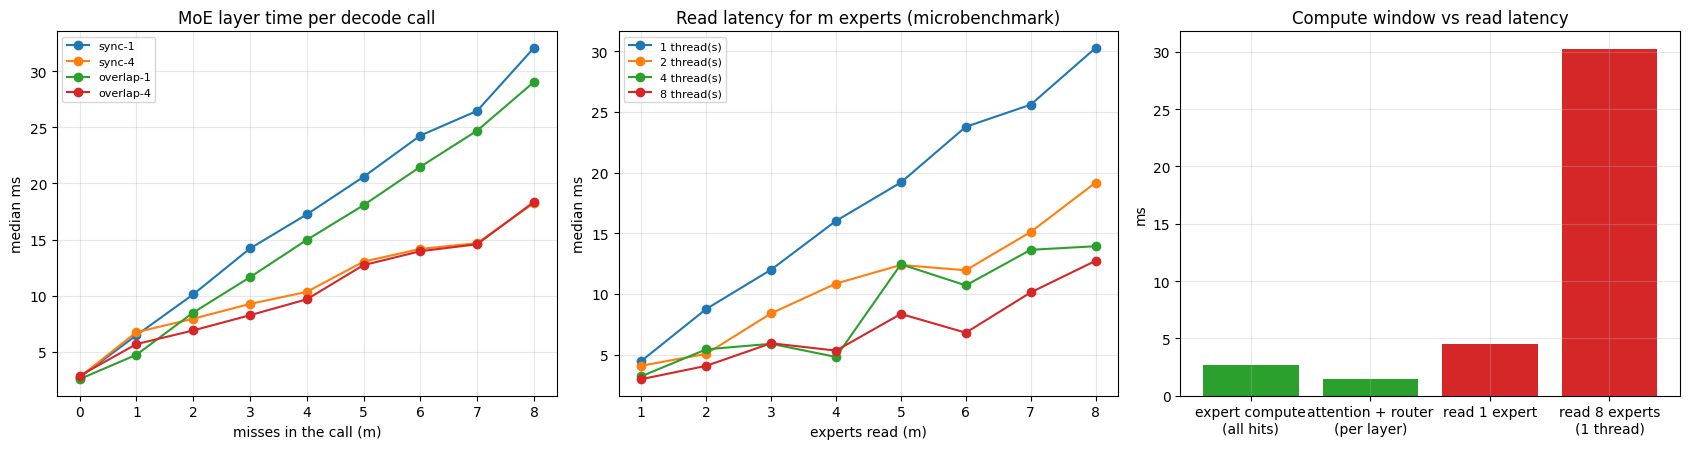

In [7]:
dec = calls[calls.phase == 'decode']
t = dec.groupby(['m', 'mode']).t_moe_ms.median().unstack()[list(MODES)]
counts = dec[dec['mode'] == 'sync-1'].groupby('m').size().rename('calls')
base = t.loc[0] if 0 in t.index else t.min()
stall = t - base
print('Median T_moe per decode call (ms), by misses m:')
display(t.join(counts).style.format('{:.2f}', subset=list(MODES)))
mask = 1 - stall['overlap-1'] / stall['sync-1']
print('Share of the sync-1 stall hidden by overlap-1, by m:')
display(mask.drop(0, errors='ignore').to_frame('hidden share').T.style.format('{:.0%}'))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for mname in MODES:
    axes[0].plot(t.index, t[mname], '-o', label=mname)
axes[0].set_xlabel('misses in the call (m)'); axes[0].set_ylabel('median ms'); axes[0].set_title('MoE layer time per decode call')
for T in mt.columns:
    axes[1].plot(mt.index, mt[T], '-o', label=f'{T} thread(s)')
axes[1].set_xlabel('experts read (m)'); axes[1].set_ylabel('median ms'); axes[1].set_title('Read latency for m experts (microbenchmark)')
w = dec[dec['mode'] == 'sync-1']
window = w[w.m == 0].t_moe_ms.median() if (w.m == 0).any() else np.nan
attn = w.route_wait_ms.median()
axes[2].bar(['expert compute\n(all hits)', 'attention + router\n(per layer)', 'read 1 expert', 'read 8 experts\n(1 thread)'],
            [window, attn, mt.loc[1, mt.columns[0]], mt.loc[8, mt.columns[0]]], color=['C2', 'C2', 'C3', 'C3'])
axes[2].set_ylabel('ms'); axes[2].set_title('Compute window vs read latency')
for ax in axes[:2]:
    ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / 'axis4_overlap.png', dpi=150, bbox_inches='tight'); plt.show()

## Hypothesis check (descriptive)

In [8]:
one = mt.loc[1, mt.columns[0]]
print(f'Compute available per layer once routing is known (all-hit expert compute): {window:.2f} ms')
print(f'Attention + router per layer (cannot overlap this layer\'s loads): {attn:.2f} ms')
print(f'Reading ONE expert: {one:.2f} ms  ->  the hit-compute window covers at most {window / one:.0%} of one miss.')
for m in [1, 2, 4, 8]:
    if m in stall.index:
        print(f'm={m}: exposed stall sync-1 {stall.loc[m, "sync-1"]:.1f} ms | sync-4 {stall.loc[m, "sync-4"]:.1f} ms | '
              f'overlap-1 {stall.loc[m, "overlap-1"]:.1f} ms | overlap-4 {stall.loc[m, "overlap-4"]:.1f} ms')
best = runs.set_index('mode').decode_tok_s
print(f'\nDecode throughput: ' + ', '.join(f'{k} {v:.2f}' for k, v in best.items()) + ' tok/s')
print('Parallel reads attack the read time itself; overlap can only hide up to the compute window.')

Compute available per layer once routing is known (all-hit expert compute): 2.69 ms
Attention + router per layer (cannot overlap this layer's loads): 1.47 ms
Reading ONE expert: 4.48 ms  ->  the hit-compute window covers at most 60% of one miss.
m=1: exposed stall sync-1 3.8 ms | sync-4 4.0 ms | overlap-1 2.2 ms | overlap-4 2.8 ms
m=2: exposed stall sync-1 7.4 ms | sync-4 5.2 ms | overlap-1 5.9 ms | overlap-4 4.0 ms
m=4: exposed stall sync-1 14.5 ms | sync-4 7.6 ms | overlap-1 12.4 ms | overlap-4 6.8 ms
m=8: exposed stall sync-1 29.4 ms | sync-4 15.5 ms | overlap-1 26.5 ms | overlap-4 15.5 ms

Decode throughput: sync-1 3.01, sync-4 4.55, overlap-1 3.56, overlap-4 4.76 tok/s
Parallel reads attack the read time itself; overlap can only hide up to the compute window.
